# Підключення Google Диску та налаштування графіків

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from google.colab import drive

drive.mount("/content/drive")

DRIVE_DIR = Path("/content/drive/MyDrive/rag-arxiv/data")
PARQUET_DIR = DRIVE_DIR / "arxiv_cs.parquet"
STATS_PATH = DRIVE_DIR / "prep_stats.json"
FIGURES_DIR = DRIVE_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

assert PARQUET_DIR.exists(), f"Не знайдено папку {PARQUET_DIR}"
assert STATS_PATH.exists(), f"Не знайдено файл {STATS_PATH}"

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

print("Шляхи перевірено. Графіки зберігатимуться в:", FIGURES_DIR)

Mounted at /content/drive
Шляхи перевірено. Графіки зберігатимуться в: /content/drive/MyDrive/rag-arxiv/data/figures


# Аналіз пайплайну PySpark: воронка відсіву та час виконання
Ця комірка працює виключно з prep_stats.json, виводить зведену таблицю та будує подвійний графік для демонстрації аспекту Big Data

,step,label,count,dropped,kept_pct_of_raw,step_time_sec
0,raw_json,Сирий датасет arXiv,3261651,0,100.00,46.45
1,filter_cs,Фільтр категорій cs.*,1059662,2201989,32.49,80.28
2,clean_and_validate,"Очищення тексту, len(abstract) >= 100, валідни...",1059136,526,32.47,151.91
3,dedup_arxiv_id,Дедуплікація за arxiv_id,1059136,0,32.47,72.30
4,dedup_text_hash,Дедуплікація за хешем тексту (SHA-256),1058983,153,32.47,94.98


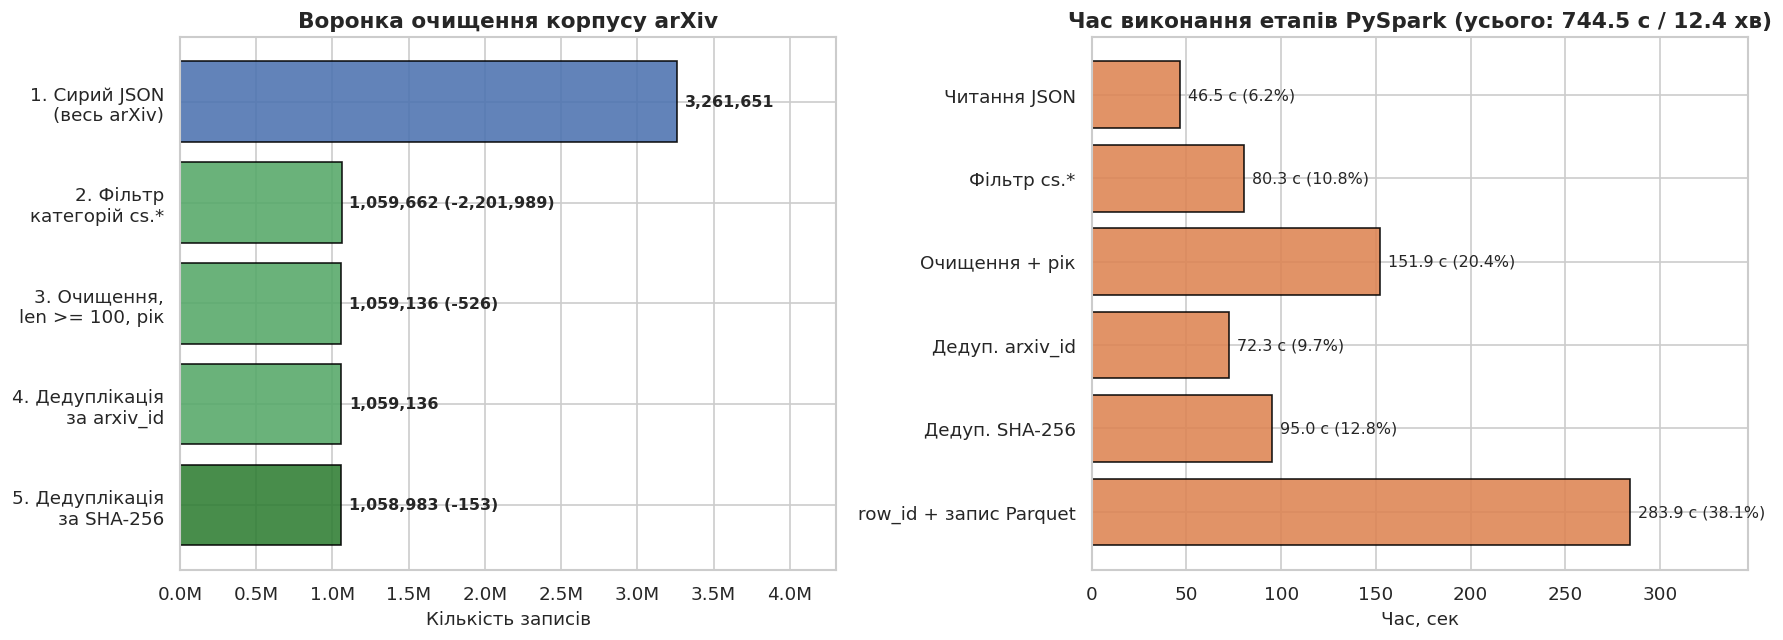

In [2]:
with open(STATS_PATH, "r", encoding="utf-8") as f:
    stats = json.load(f)

funnel_df = pd.DataFrame(stats["funnel"])
display(funnel_df[["step", "label", "count", "dropped", "kept_pct_of_raw", "step_time_sec"]])

# Словник коротких підписів для графіка
short_labels = {
    "raw_json": "1. Сирий JSON\n(весь arXiv)",
    "filter_cs": "2. Фільтр\nкатегорій cs.*",
    "clean_and_validate": "3. Очищення,\nlen >= 100, рік",
    "dedup_arxiv_id": "4. Дедуплікація\nза arxiv_id",
    "dedup_text_hash": "5. Дедуплікація\nза SHA-256",
}

timing_labels = {
    "raw_json": "Читання JSON",
    "filter_cs": "Фільтр cs.*",
    "clean_and_validate": "Очищення + рік",
    "dedup_arxiv_id": "Дедуп. arxiv_id",
    "dedup_text_hash": "Дедуп. SHA-256",
    "assign_row_id_and_write_parquet": "row_id + запис Parquet",
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Графік 1: Воронка відсіву
y_labels = [short_labels.get(s, s) for s in funnel_df["step"]]
counts = funnel_df["count"].values
dropped = funnel_df["dropped"].values
colors_funnel = ["#4C72B0", "#55A868", "#55A868", "#55A868", "#2E7D32"]

bars1 = ax1.barh(y_labels[::-1], counts[::-1], color=colors_funnel[::-1], edgecolor="black", alpha=0.88)
ax1.set_title("Воронка очищення корпусу arXiv")
ax1.set_xlabel("Кількість записів")
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
ax1.set_xlim(0, counts.max() * 1.32)

for bar, cnt, drp in zip(bars1, counts[::-1], dropped[::-1]):
    delta_txt = f" (-{drp:,})" if drp > 0 else ""
    ax1.text(
        bar.get_width() + counts.max() * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{cnt:,}{delta_txt}",
        va="center",
        fontsize=9.5,
        fontweight="bold",
    )

# Графік 2: Час виконання етапів
timings = stats["timings_sec"]
t_keys = [k for k in timings.keys() if k != "total_pipeline_sec"]
t_names = [timing_labels.get(k, k) for k in t_keys]
t_vals = [timings[k] for k in t_keys]
total_sec = timings["total_pipeline_sec"]

bars2 = ax2.barh(t_names[::-1], t_vals[::-1], color="#DD8452", edgecolor="black", alpha=0.88)
ax2.set_title(f"Час виконання етапів PySpark (усього: {total_sec:.1f} с / {total_sec/60:.1f} хв)")
ax2.set_xlabel("Час, сек")
ax2.set_xlim(0, max(t_vals) * 1.22)

for bar, val in zip(bars2, t_vals[::-1]):
    pct = 100.0 * val / total_sec
    ax2.text(
        bar.get_width() + max(t_vals) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1f} с ({pct:.1f}%)",
        va="center",
        fontsize=9.5,
    )

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_pipeline_funnel_and_time.png", dpi=200, bbox_inches="tight")
plt.show()

# Швидкий збір статистик по всіх 12 Parquet-файлах
Читаємо папку партиція за партицією, збираючи роки, лічильники категорій і довжини анотацій у компактні масиви NumPy (уся пам'ять — менше 300 МБ).

In [3]:
parquet_files = sorted(PARQUET_DIR.glob("part-*.parquet"))
print(f"Знайдено Parquet-файлів: {len(parquet_files)}")

years_chunks = []
char_len_chunks = []
word_len_chunks = []

cs_cat_counter = Counter()
primary_cat_counter = Counter()
non_cs_cat_counter = Counter()
cs_tags_per_paper = Counter()

for pf in parquet_files:
    part_df = pd.read_parquet(pf, columns=["year", "categories", "abstract"])

    years_chunks.append(part_df["year"].to_numpy(dtype=np.int32))
    char_len_chunks.append(part_df["abstract"].str.len().to_numpy(dtype=np.int32))
    word_len_chunks.append(part_df["abstract"].str.split().str.len().to_numpy(dtype=np.int32))

    for cat_str in part_df["categories"]:
        tags = cat_str.split()
        if not tags:
            continue
        primary_cat_counter[tags[0]] += 1
        cs_tags = [t for t in tags if t.startswith("cs.")]
        other_tags = [t for t in tags if not t.startswith("cs.")]
        cs_tags_per_paper[len(cs_tags)] += 1
        cs_cat_counter.update(cs_tags)
        non_cs_cat_counter.update(other_tags)

years = np.concatenate(years_chunks)
char_lens = np.concatenate(char_len_chunks)
word_lens = np.concatenate(word_len_chunks)
total_docs = len(years)

print(f"Оброблено документів: {total_docs:,}")
print(f"Діапазон років: {years.min()} – {years.max()}")
print(f"Унікальних cs.* категорій: {len(cs_cat_counter)}")

# Перевірка кількох перших записів для візуального контролю якості
sample_rows = pq.read_table(parquet_files[0]).slice(0, 3).to_pandas()
display(sample_rows[["row_id", "arxiv_id", "year", "categories", "title"]])

Знайдено Parquet-файлів: 12
Оброблено документів: 1,058,983
Діапазон років: 1990 – 2026
Унікальних cs.* категорій: 40


,row_id,arxiv_id,year,categories,title
0,0,0704.0002,2007,math.CO cs.CG,Sparsity-certifying Graph Decompositions
1,1,0704.0022,2007,math.NA cs.NA,Stochastic Lie group integrators
2,2,0704.0046,2007,quant-ph cs.IT math.IT,A limit relation for entropy and channel capac...


# Розподіл статей за роками
Показує експоненційне зростання публікацій у Computer Science, а також рахує частку статей за останні 5 років.

Піковий рік: 2026 (185,357 статей)
Частка статей за 2022–2026 рр.: 60.9%


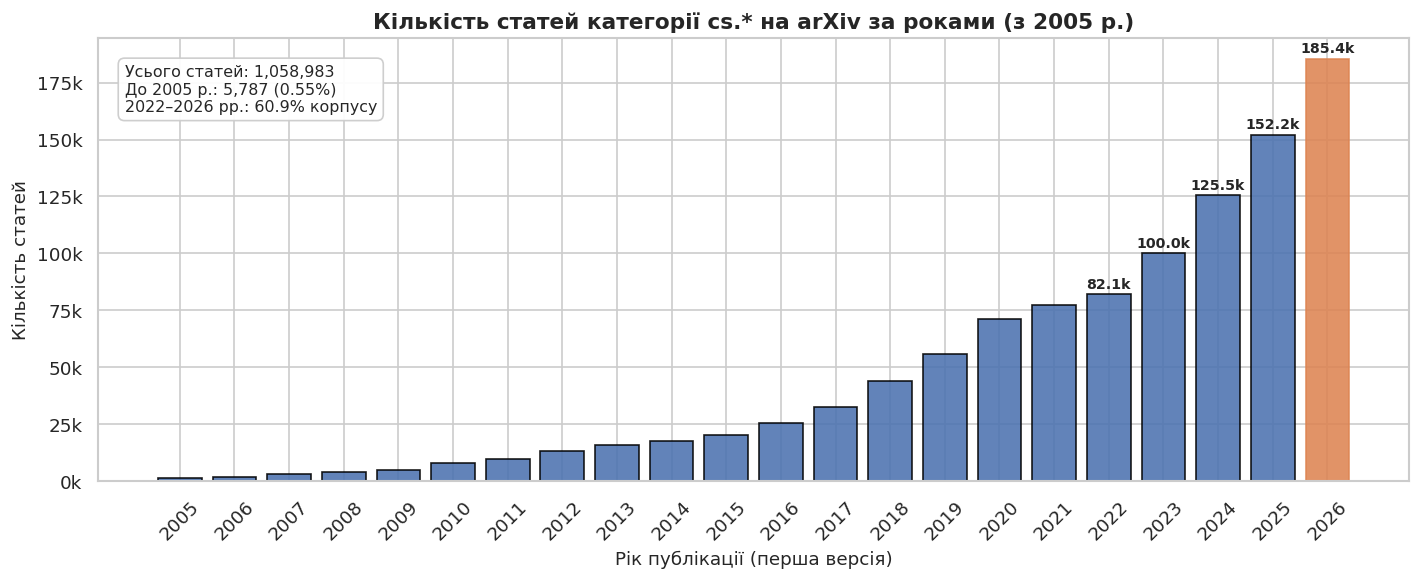

In [4]:
year_counts = pd.Series(years).value_counts().sort_index()
recent_5y_start = int(year_counts.index.max()) - 4
recent_5y_share = 100.0 * year_counts.loc[recent_5y_start:].sum() / total_docs

print(f"Піковий рік: {year_counts.idxmax()} ({year_counts.max():,} статей)")
print(f"Частка статей за {recent_5y_start}–{year_counts.index.max()} рр.: {recent_5y_share:.1f}%")

# Для читабельності графіка агрегуємо ранні роки до 2005 (або показуємо від 2005)
plot_years = year_counts.loc[year_counts.index >= 2005]
pre_2005_count = int(year_counts.loc[year_counts.index < 2005].sum())

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(plot_years.index, plot_years.values, color="#4C72B0", edgecolor="black", alpha=0.88)

# Виділяємо останній рік іншим відтінком, якщо він ще не завершений повністю
bars[-1].set_color("#DD8452")

ax.set_title("Кількість статей категорії cs.* на arXiv за роками (з 2005 р.)")
ax.set_xlabel("Рік публікації (перша версія)")
ax.set_ylabel("Кількість статей")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x/1000)}k"))
ax.set_xticks(plot_years.index)
ax.tick_params(axis="x", rotation=45)

# Підписи над останніми 5 стовпцями
for yr, val in list(plot_years.items())[-5:]:
    ax.text(yr, val + plot_years.max() * 0.015, f"{val/1000:.1f}k", ha="center", fontsize=8.5, fontweight="bold")

note_text = (
    f"Усього статей: {total_docs:,}\n"
    f"До 2005 р.: {pre_2005_count:,} ({100*pre_2005_count/total_docs:.2f}%)\n"
    f"{recent_5y_start}–{plot_years.index.max()} рр.: {recent_5y_share:.1f}% корпусу"
)
ax.text(
    0.02, 0.94, note_text,
    transform=ax.transAxes, va="top", fontsize=9.5,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#cccccc", alpha=0.95),
)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_papers_by_year.png", dpi=200, bbox_inches="tight")
plt.show()

# Розподіл статей за категоріями cs.* та суміжними областями
Оскільки одна стаття на arXiv часто має кілька тегів (наприклад, cs.CV cs.LG), рахуємо повну частоту згадувань кожної підкатегорії cs.* із зрозумілими розшифровками для слайдів, а також топ суміжних не-CS тегів (наприклад, stat.ML, eess.IV).

,category,label,count,share_of_docs_pct
0,cs.LG,cs.LG — Machine Learning,300212,28.35
1,cs.CV,cs.CV — Computer Vision,214287,20.24
2,cs.AI,cs.AI — Artificial Intelligence,213982,20.21
3,cs.CL,cs.CL — Computation & Language (NLP),125867,11.89
4,cs.RO,cs.RO — Robotics,63057,5.95
5,cs.IT,cs.IT — Information Theory,57363,5.42
6,cs.CR,cs.CR — Cryptography & Security,54649,5.16
7,cs.NA,cs.NA — Numerical Analysis,53159,5.02
8,cs.SY,cs.SY — Systems & Control,50488,4.77
9,cs.HC,cs.HC — Human-Computer Interaction,34285,3.24


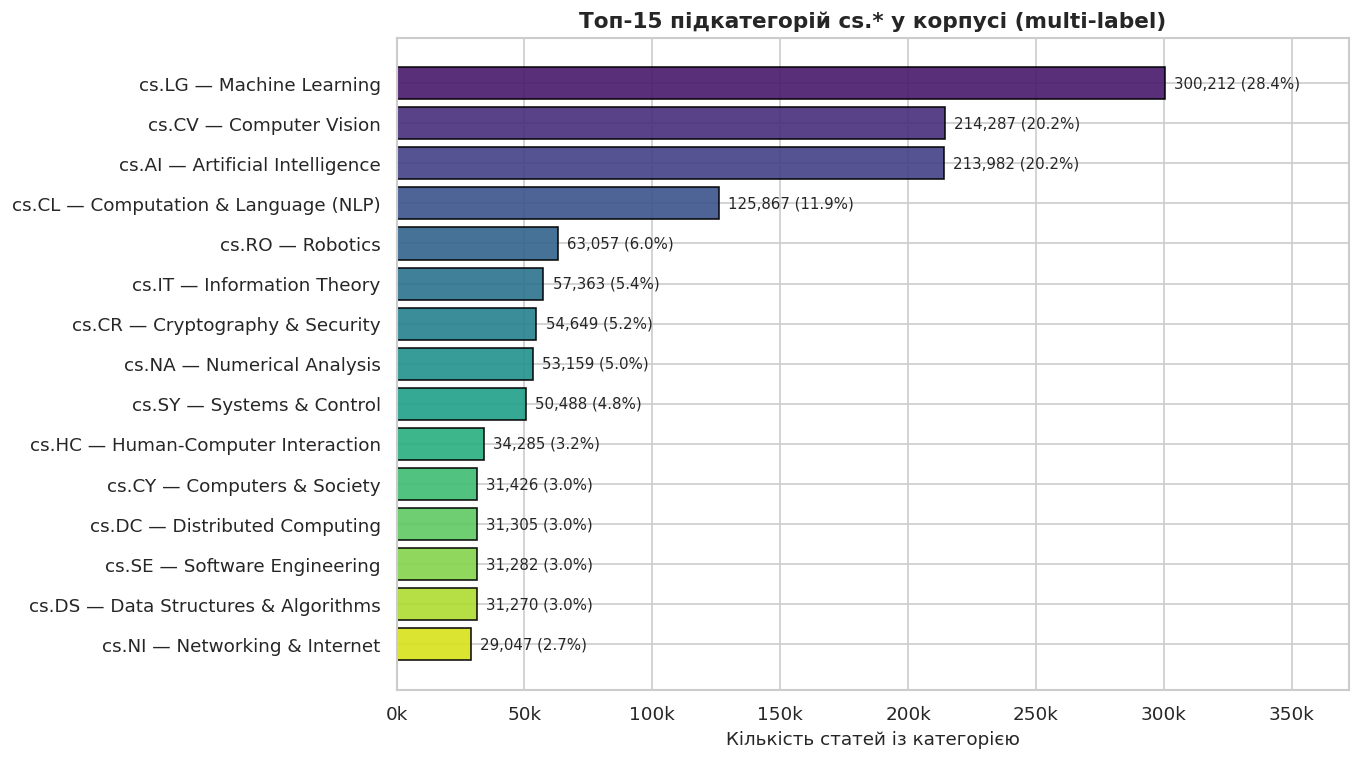


Середня кількість cs.* тегів на статтю: 1.52 (2+ тегів мають 39.1% статей)
Топ-5 суміжних (не cs.*) категорій: [('stat.ML', 73306), ('math.IT', 57363), ('math.NA', 53159), ('eess.SY', 50486), ('math.OC', 29904)]


In [5]:
CS_DESCRIPTIONS = {
    "cs.CV": "Computer Vision",
    "cs.LG": "Machine Learning",
    "cs.CL": "Computation & Language (NLP)",
    "cs.AI": "Artificial Intelligence",
    "cs.IT": "Information Theory",
    "cs.RO": "Robotics",
    "cs.CR": "Cryptography & Security",
    "cs.SY": "Systems & Control",
    "cs.DS": "Data Structures & Algorithms",
    "cs.SE": "Software Engineering",
    "cs.NI": "Networking & Internet",
    "cs.SI": "Social & Information Networks",
    "cs.HC": "Human-Computer Interaction",
    "cs.IR": "Information Retrieval",
    "cs.DC": "Distributed Computing",
    "cs.CY": "Computers & Society",
    "cs.GT": "CS & Game Theory",
    "cs.LO": "Logic in CS",
    "cs.NE": "Neural & Evolutionary",
    "cs.LO": "Logic in CS",
    "cs.NA": "Numerical Analysis",
    "cs.SD": "Sound",
    "cs.DB": "Databases",
    "cs.PL": "Programming Languages",
    "cs.CC": "Computational Complexity",
    "cs.DM": "Discrete Mathematics",
}

top_n = 15
top_cs = cs_cat_counter.most_common(top_n)
top_cs_df = pd.DataFrame(top_cs, columns=["category", "count"])
top_cs_df["share_of_docs_pct"] = (100.0 * top_cs_df["count"] / total_docs).round(2)
top_cs_df["label"] = top_cs_df["category"].apply(
    lambda c: f"{c} — {CS_DESCRIPTIONS[c]}" if c in CS_DESCRIPTIONS else c
)

display(top_cs_df[["category", "label", "count", "share_of_docs_pct"]])

fig, ax = plt.subplots(figsize=(11.5, 6.5))
bars = ax.barh(
    top_cs_df["label"][::-1],
    top_cs_df["count"][::-1],
    color=sns.color_palette("viridis", top_n)[::-1],
    edgecolor="black",
    alpha=0.9,
)

ax.set_title(f"Топ-{top_n} підкатегорій cs.* у корпусі (multi-label)")
ax.set_xlabel("Кількість статей із категорією")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x/1000)}k"))
ax.set_xlim(0, top_cs_df["count"].max() * 1.24)

for bar, cnt, pct in zip(bars, top_cs_df["count"][::-1], top_cs_df["share_of_docs_pct"][::-1]):
    ax.text(
        bar.get_width() + top_cs_df["count"].max() * 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{cnt:,} ({pct:.1f}%)",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_top_cs_categories.png", dpi=200, bbox_inches="tight")
plt.show()

# Додаткова статистика по мультимітковості та суміжних областях
avg_cs_tags = sum(k * v for k, v in cs_tags_per_paper.items()) / total_docs
multi_cs_pct = 100.0 * sum(v for k, v in cs_tags_per_paper.items() if k > 1) / total_docs
print(f"\nСередня кількість cs.* тегів на статтю: {avg_cs_tags:.2f} (2+ тегів мають {multi_cs_pct:.1f}% статей)")
print("Топ-5 суміжних (не cs.*) категорій:", non_cs_cat_counter.most_common(5))

# Розподіл довжини анотацій і зв'язок із лімітами моделей
Тут рахуються перцентилі довжини в символах, словах та орієнтовних токенах (слова × 1.33). На графіку також позначено ліміти токенів популярних моделей ембедінгів (all-MiniLM-L6-v2 має обмеження 256 токенів, bge-small-en-v1.5 — 512 токенів)

,Метрика,Мін,P25,Медіана,Середнє,P90,P95,P99,Макс
0,Символи (abstract),100,957,1213,1207.9,1711,1829,1911,4080
1,Слова (abstract),10,136,170,170.0,239,256,283,588
2,Орієнтовні токени (~1.33×слова),13,180,226,225.6,317,340,376,782


Частка анотацій > ~256 токенів (ліміт all-MiniLM-L6-v2): 32.6%
Частка анотацій > ~512 токенів (ліміт bge-small / e5-small): 0.01%


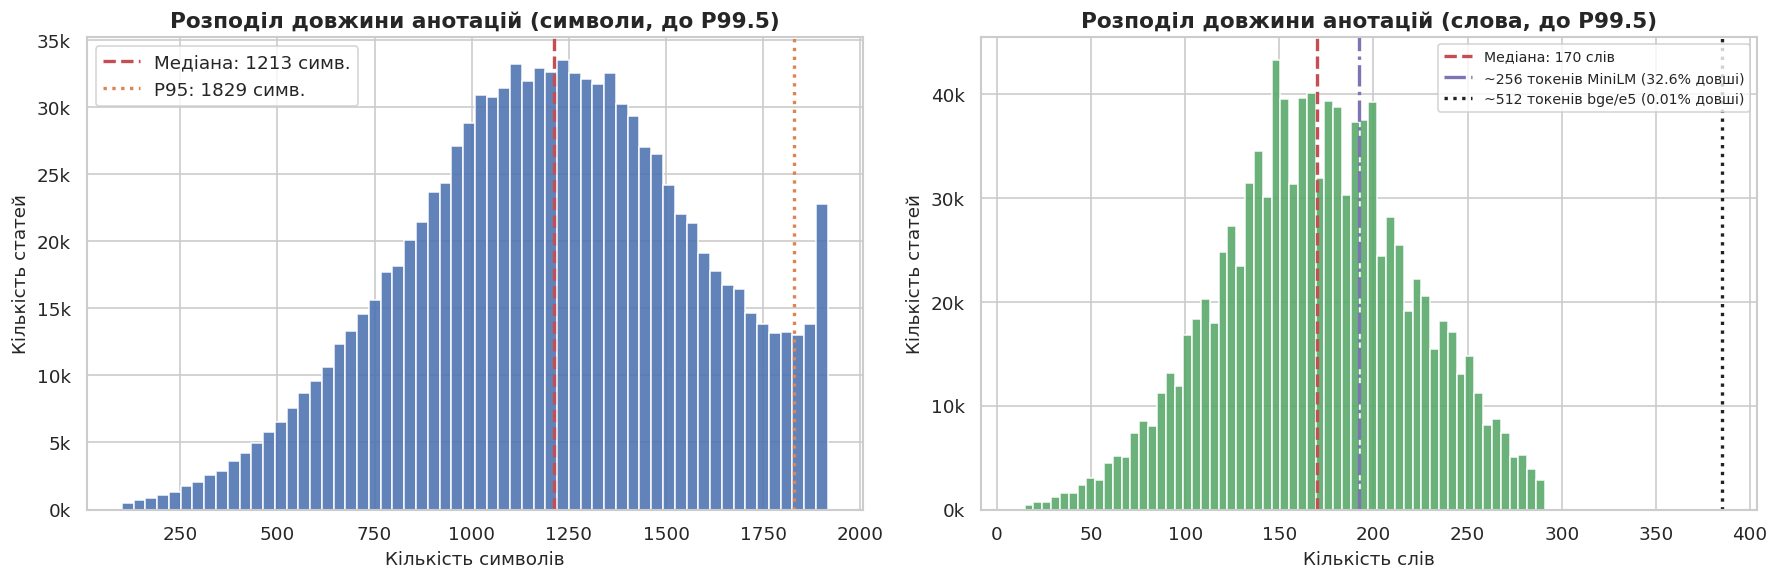

In [6]:
approx_tokens = (word_lens * 1.33).astype(np.int32)

def summarize_array(arr: np.ndarray, name: str) -> dict:
    return {
        "Метрика": name,
        "Мін": int(np.min(arr)),
        "P25": int(np.percentile(arr, 25)),
        "Медіана": int(np.median(arr)),
        "Середнє": round(float(np.mean(arr)), 1),
        "P90": int(np.percentile(arr, 90)),
        "P95": int(np.percentile(arr, 95)),
        "P99": int(np.percentile(arr, 99)),
        "Макс": int(np.max(arr)),
    }

len_summary_df = pd.DataFrame([
    summarize_array(char_lens, "Символи (abstract)"),
    summarize_array(word_lens, "Слова (abstract)"),
    summarize_array(approx_tokens, "Орієнтовні токени (~1.33×слова)"),
])
display(len_summary_df)

pct_gt_256 = 100.0 * np.mean(approx_tokens > 256)
pct_gt_512 = 100.0 * np.mean(approx_tokens > 512)
print(f"Частка анотацій > ~256 токенів (ліміт all-MiniLM-L6-v2): {pct_gt_256:.1f}%")
print(f"Частка анотацій > ~512 токенів (ліміт bge-small / e5-small): {pct_gt_512:.2f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Графік 1: Довжина в символах (обрізаємо хвіст на P99.5 для наочності)
char_cap = int(np.percentile(char_lens, 99.5))
ax1.hist(char_lens[char_lens <= char_cap], bins=60, color="#4C72B0", edgecolor="white", alpha=0.88)
ax1.axvline(np.median(char_lens), color="#C44E52", linestyle="--", linewidth=2, label=f"Медіана: {int(np.median(char_lens))} симв.")
ax1.axvline(np.percentile(char_lens, 95), color="#DD8452", linestyle=":", linewidth=2, label=f"P95: {int(np.percentile(char_lens, 95))} симв.")
ax1.set_title("Розподіл довжини анотацій (символи, до P99.5)")
ax1.set_xlabel("Кількість символів")
ax1.set_ylabel("Кількість статей")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x/1000)}k"))
ax1.legend()

# Графік 2: Довжина в словах + орієнтовні ліміти моделей ембедінгів
word_cap = int(np.percentile(word_lens, 99.5))
ax2.hist(word_lens[word_lens <= word_cap], bins=60, color="#55A868", edgecolor="white", alpha=0.88)
ax2.axvline(np.median(word_lens), color="#C44E52", linestyle="--", linewidth=2, label=f"Медіана: {int(np.median(word_lens))} слів")
ax2.axvline(256 / 1.33, color="#8172B3", linestyle="-.", linewidth=2, label=f"~256 токенів MiniLM ({pct_gt_256:.1f}% довші)")
ax2.axvline(512 / 1.33, color="#222222", linestyle=":", linewidth=2, label=f"~512 токенів bge/e5 ({pct_gt_512:.2f}% довші)")
ax2.set_title("Розподіл довжини анотацій (слова, до P99.5)")
ax2.set_xlabel("Кількість слів")
ax2.set_ylabel("Кількість статей")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x/1000)}k"))
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_abstract_length_dist.png", dpi=200, bbox_inches="tight")
plt.show()

# Готова шпаргалка цифр для слайдів (Етап 3) та README

In [7]:
raw_n = stats["funnel"][0]["count"]
final_n = stats["output_info"]["final_rows"]
size_mb = stats["output_info"]["total_size_mb"]
total_t = stats["timings_sec"]["total_pipeline_sec"]

print("=== КЛЮЧОВІ ЦИФРИ ДЛЯ СЛАЙДІВ (ЕТАП 3) ===")
print(f"• Сирий датасет:        {raw_n:,} статей (JSON 5.32 ГБ)")
print(f"• Після фільтру cs.*:   {stats['funnel'][1]['count']:,} ({stats['funnel'][1]['kept_pct_of_raw']}% від сирого)")
print(f"• Відсіяно чисткою:     {stats['funnel'][2]['dropped']:,} (короткі <100 симв. / битий рік)")
print(f"• Дублікатів arxiv_id:  {stats['funnel'][3]['dropped']:,}")
print(f"• Дублікатів за текстом:{stats['funnel'][4]['dropped']:,} (SHA-256)")
print(f"• Фінальний корпус:     {final_n:,} статей у {stats['output_info']['num_parquet_files']} Parquet-файлах ({size_mb:.1f} МБ)")
print(f"• Час роботи PySpark:   {total_t:.1f} с ({total_t/60:.1f} хв), ~{int(raw_n / total_t):,} рядків/с")
print(f"• Медіанна анотація:    {int(np.median(word_lens))} слів / {int(np.median(char_lens))} символів (~{int(np.median(approx_tokens))} токенів)")
print(f"• Топ-3 категорії:      " + ", ".join(f"{c} ({n:,})" for c, n in cs_cat_counter.most_common(3)))
print(f"• Збережені графіки:    {[p.name for p in sorted(FIGURES_DIR.glob('*.png'))]}")

=== КЛЮЧОВІ ЦИФРИ ДЛЯ СЛАЙДІВ (ЕТАП 3) ===
• Сирий датасет:        3,261,651 статей (JSON 5.32 ГБ)
• Після фільтру cs.*:   1,059,662 (32.49% від сирого)
• Відсіяно чисткою:     526 (короткі <100 симв. / битий рік)
• Дублікатів arxiv_id:  0
• Дублікатів за текстом:153 (SHA-256)
• Фінальний корпус:     1,058,983 статей у 12 Parquet-файлах (1477.3 МБ)
• Час роботи PySpark:   744.5 с (12.4 хв), ~4,380 рядків/с
• Медіанна анотація:    170 слів / 1213 символів (~226 токенів)
• Топ-3 категорії:      cs.LG (300,212), cs.CV (214,287), cs.AI (213,982)
• Збережені графіки:    ['01_pipeline_funnel_and_time.png', '02_papers_by_year.png', '03_top_cs_categories.png', '04_abstract_length_dist.png']
